# T3.7 — Router Dataset Preparation
## Collect 20,000 balanced images from all 4 scripts → save as ready-to-use folder

This notebook extracts images from all four script datasets, assigns script-level labels,
and saves them into a single clean folder structure that the Router CNN training notebook
can consume directly.

### Output folder layout
```
/kaggle/working/router_dataset/
    devanagari/
        character_01_ka/   img_000001.png  img_000002.png ...
        character_02_kha/  ...
        ...
    tamil/
        class_001/         img_000001.png ...
        ...
    bengali/
        class_01/          img_000001.png ...
        ...
    kannada/
        class_0/           img_000001.png ...
        ...
```
Each script folder gets exactly **5,000 images** spread across **all available classes**
(as evenly as possible), giving **20,000 total**.

---
### Datasets to attach before running
| Dataset | Kaggle slug |
|---------|-------------|
| Devanagari | `rishianand/devanagari-character-set` |
| Tamil uTHCD | `faizalhajamohideen/uthcdtamil-handwritten-database` |
| BanglaLekha Bengali | `asefjamilajwad2/banglalekha-isolated` |
| Kannada-MNIST | `competitions/Kannada-MNIST` |

> **GPU not required** — this is pure data processing.

## 0. Imports

In [12]:
import os, random, shutil, json, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print('Imports OK')

Imports OK


## 1. Configuration

In [13]:
# ── Sampling targets ──────────────────────────────────────────────────────
IMAGES_PER_SCRIPT = 13_000      # 5k × 4 scripts = 20k total
IMG_OUT_SIZE      = 32         # all saved images resized to 32×32

# uTHCD split to use: 'a'=70/30  'b'=80/20  'c'=85/15  'd'=90/10
TAMIL_SPLIT = 'b'

# ── Paths ─────────────────────────────────────────────────────────────────
INPUT_ROOT  = Path('/kaggle/input')
OUT_ROOT    = Path('/kaggle/working/router_dataset')

SCRIPTS = ['devanagari', 'tamil', 'bengali', 'kannada']
for s in SCRIPTS:
    (OUT_ROOT / s).mkdir(parents=True, exist_ok=True)

print(f'Output root  : {OUT_ROOT}')
print(f'Images/script: {IMAGES_PER_SCRIPT}')
print(f'Output size  : {IMG_OUT_SIZE}×{IMG_OUT_SIZE} px')

Output root  : /kaggle/working/router_dataset
Images/script: 13000
Output size  : 32×32 px


## 2. Utility Functions

In [14]:
def save_image(arr_or_pil, out_path: Path):
    """
    Save a numpy uint8 array or PIL image as a 32×32 grayscale PNG.
    Inverts dark-background images so characters are dark on white.
    """
    if isinstance(arr_or_pil, np.ndarray):
        img = Image.fromarray(arr_or_pil.astype(np.uint8), mode='L')
    else:
        img = arr_or_pil.convert('L')

    img = img.resize((IMG_OUT_SIZE, IMG_OUT_SIZE), Image.LANCZOS)

    # Normalise polarity: ensure character strokes are dark (low pixel value)
    arr = np.array(img)
    if arr.mean() < 100:          # dark background → invert
        arr = 255 - arr
    Image.fromarray(arr).save(out_path, format='PNG', optimize=False)


def balanced_sample(class_to_paths: dict, total: int) -> dict:
    """
    Given {class_name: [paths]}, return a new dict with paths
    balanced so that the total count equals `total`.
    Spreads images across ALL classes before allowing repeats.
    """
    classes   = sorted(class_to_paths.keys())
    n_classes = len(classes)
    per_class = max(1, total // n_classes)
    remainder = total - per_class * n_classes

    result = {}
    for i, cls in enumerate(classes):
        quota  = per_class + (1 if i < remainder else 0)
        paths  = class_to_paths[cls]
        # Sample with replacement only if we need more than available
        chosen = random.choices(paths, k=quota) if quota > len(paths) \
                 else random.sample(paths, quota)
        result[cls] = chosen
    return result


def find_dir(root: Path, keywords: list):
    for d in sorted(root.iterdir()):
        if d.is_dir() and any(k in d.name.lower() for k in keywords):
            return d
    return None


def find_file(root: Path, keywords: list, ext: str):
    for p in sorted(root.rglob(f'*{ext}')):
        if any(k in p.name.lower() for k in keywords):
            return p
    return None


print('Utility functions defined.')

Utility functions defined.


## 3. Detect Dataset Paths

In [15]:
# ── Auto-detect ────────────────────────────────────────────────────────────
PATHS = {
    # 'devanagari_dir' : find_dir(INPUT_ROOT,  ['devanagari', 'hindi']),
    # 'tamil_h5'       : find_file(INPUT_ROOT, [f'uTHCD_{TAMIL_SPLIT}', 'uthcd'], '.h5'),
    # 'bengali_dir'    : find_dir(INPUT_ROOT,  ['bangla', 'bengali', 'banglalekha']),
    # 'kannada_csv'    : find_file(INPUT_ROOT, ['train'], '.csv'),
}

# Fallback: if Tamil .h5 not found, grab any .h5
    # if PATHS['tamil_h5'] is None:
    #     all_h5 = sorted(INPUT_ROOT.rglob('*.h5'))
    #     PATHS['tamil_h5'] = all_h5[0] if all_h5 else None
    
    # print('Detected paths:')
    # for k, v in PATHS.items():
    #     ok = '✓' if v and Path(v).exists() else '✗  NOT FOUND'
    #     print(f'  [{ok}] {k:20s} → {v}')

# ── MANUAL OVERRIDE — uncomment & edit if auto-detect missed a dataset ────
PATHS['devanagari_dir'] = Path("/kaggle/input/datasets/medahmedkrichen/devanagari-handwritten-character-datase/DevanagariHandwrittenCharacterDataset/Train")
PATHS['tamil_h5']       = Path("/kaggle/input/datasets/faizalhajamohideen/uthcdtamil-handwritten-database/uTHCD_d(90-10-split)/90-10-split/uTHCD_9010_compressed.h5")
PATHS['bengali_dir']    = Path("/kaggle/input/datasets/mdnaorezahabib/banglalekha-isolated/BanglaLekha-Isolated/Images")
PATHS['kannada_csv']    = Path('/kaggle/input/competitions/Kannada-MNIST/train.csv')

## 4. Extract — Devanagari
**Source:** folder-of-folders, 46 classes, 32×32 PNG images  
**Format:** `Train/character_01_ka/*.png`, `Test/...`  
**Target:** 5,000 images across all 46 classes (~109 per class)

In [16]:
deva_stats = {'status': 'skipped', 'classes': 0, 'images': 0}

if PATHS['devanagari_dir']:
    deva_root = PATHS['devanagari_dir']

    # Collect all image paths grouped by class folder name
    class_to_paths = defaultdict(list)
    
    # glob('*/*.png') exactly matches deva_root/class_name/image.png
    for p in deva_root.glob('*/*.png'):
        cls_name = p.parent.name   # Extracts 'class_name'
        class_to_paths[cls_name].append(p)

    print(f'Devanagari: found {len(class_to_paths)} classes, '
          f'{sum(len(v) for v in class_to_paths.values()):,} total images')

    # Balanced sample
    sampled = balanced_sample(dict(class_to_paths), IMAGES_PER_SCRIPT)

    out_base = OUT_ROOT / 'devanagari'
    saved = 0
    for cls_name, paths in tqdm(sampled.items(), desc='Devanagari'):
        cls_dir = out_base / cls_name
        cls_dir.mkdir(parents=True, exist_ok=True) # parents=True ensures out_base is created if missing
        
        for p in paths:
            out_path = cls_dir / f'img_{saved:06d}.png'
            try:
                pil = Image.open(p)
                save_image(pil, out_path)
                saved += 1
            except Exception:
                pass   # skip corrupt files silently

    deva_stats = {'status': 'ok', 'classes': len(sampled), 'images': saved}
    print(f'  ✓ Saved {saved:,} images across {len(sampled)} classes')
else:
    print('  ✗ Devanagari dataset not found — skipping.')

Devanagari: found 46 classes, 78,200 total images


Devanagari:   0%|          | 0/46 [00:00<?, ?it/s]

  ✓ Saved 13,000 images across 46 classes


## 5. Extract — Tamil (uTHCD)
**Source:** HDF5 file, 156 classes, 32×32 grayscale images  
**Format:** `Train Data/x_train` array (N, 32, 32), labels 1-indexed  
**Target:** 5,000 images across all 156 classes (~32 per class)

In [17]:
tamil_stats = {'status': 'skipped', 'classes': 0, 'images': 0}

if PATHS['tamil_h5'] and PATHS['tamil_h5'].exists():
    print(f'Loading HDF5: {PATHS["tamil_h5"]}')

    with h5py.File(PATHS['tamil_h5'], 'r') as f:
        # Handle slight key-name variations across uTHCD versions
        train_grp = (f.get('Train Data') or f.get('Train') or f.get('train'))
        test_grp  = (f.get('Test Data')  or f.get('Test')  or f.get('test'))

        x_tr = np.array(train_grp.get('x_train') or train_grp.get('images'))
        y_tr = np.array(train_grp.get('y_train') or train_grp.get('labels'))

        # Also pull test set — more images = better class coverage
        x_te = np.array(test_grp.get('x_test')  or test_grp.get('images'))
        y_te = np.array(test_grp.get('y_test')  or test_grp.get('labels'))

    # Combine train + test for maximum class coverage
    x_all = np.concatenate([x_tr, x_te], axis=0)
    y_all = np.concatenate([y_tr, y_te], axis=0)

    # Drop channel dim if present: (N,32,32,1) → (N,32,32)
    if x_all.ndim == 4:
        x_all = x_all[..., 0]

    # Scale to uint8 if needed
    if x_all.max() <= 1.0:
        x_all = (x_all * 255).astype(np.uint8)

    # Convert 1-indexed labels → 0-indexed
    if y_all.min() == 1:
        y_all = y_all - 1

    print(f'Tamil: {x_all.shape[0]:,} images, '
          f'{len(np.unique(y_all))} classes')

    # Group indices by class
    class_to_idx = defaultdict(list)
    for i, lbl in enumerate(y_all):
        class_to_idx[int(lbl)].append(i)

    # Balanced sample
    n_classes = len(class_to_idx)
    per_class = max(1, IMAGES_PER_SCRIPT // n_classes)
    remainder = IMAGES_PER_SCRIPT - per_class * n_classes

    out_base = OUT_ROOT / 'tamil'
    saved    = 0

    for i, cls in enumerate(tqdm(sorted(class_to_idx.keys()), desc='Tamil')):
        quota = per_class + (1 if i < remainder else 0)
        idxs  = class_to_idx[cls]
        chosen = (random.choices(idxs, k=quota) if quota > len(idxs)
                  else random.sample(idxs, quota))

        cls_dir = out_base / f'class_{cls+1:03d}'
        cls_dir.mkdir(exist_ok=True)

        for j, idx in enumerate(chosen):
            out_path = cls_dir / f'img_{saved:06d}.png'
            save_image(x_all[idx], out_path)
            saved += 1

    tamil_stats = {'status': 'ok', 'classes': n_classes, 'images': saved}
    print(f'  ✓ Saved {saved:,} images across {n_classes} classes')
else:
    print('  ✗ Tamil HDF5 not found — skipping.')

Loading HDF5: /kaggle/input/datasets/faizalhajamohideen/uthcdtamil-handwritten-database/uTHCD_d(90-10-split)/90-10-split/uTHCD_9010_compressed.h5
Tamil: 90,950 images, 156 classes


Tamil:   0%|          | 0/156 [00:00<?, ?it/s]

  ✓ Saved 13,000 images across 156 classes


## 6. Extract — Bengali (BanglaLekha-Isolated)
**Source:** folder-of-folders, 84 classes  
**Format:** `Images/1/*.png` … `Images/84/*.png` (variable size)  
**Target:** 5,000 images across all 84 classes (~60 per class)

In [18]:
bengali_stats = {'status': 'skipped', 'classes': 0, 'images': 0}

if PATHS['bengali_dir'] and PATHS['bengali_dir'].exists():
    ben_root = PATHS['bengali_dir']

    # BanglaLekha sometimes stores images in numbered subfolders inside an 'Images' dir
    # Handle layouts where Images/ is a subdirectory, or just use the root
    images_subdir = ben_root / 'Images'
    search_root   = images_subdir if images_subdir.exists() else ben_root

    class_to_paths = defaultdict(list)
    
    # glob('*/*.png') exactly matches search_root/class_name/image.png
    for p in search_root.glob('*/*.png'):
        cls_name = p.parent.name
        class_to_paths[cls_name].append(p)

    print(f'Bengali: found {len(class_to_paths)} classes, '
          f'{sum(len(v) for v in class_to_paths.values()):,} total images')

    sampled  = balanced_sample(dict(class_to_paths), IMAGES_PER_SCRIPT)
    out_base = OUT_ROOT / 'bengali'
    saved    = 0

    for cls_name, paths in tqdm(sampled.items(), desc='Bengali'):
        # Normalise class folder names to zero-padded for consistency (e.g., '1' -> 'class_01')
        try:
            padded = f'class_{int(cls_name):02d}'
        except ValueError:
            padded = f'class_{cls_name}'

        cls_dir = out_base / padded
        cls_dir.mkdir(parents=True, exist_ok=True) # parents=True ensures out_base is created

        for p in paths:
            out_path = cls_dir / f'img_{saved:06d}.png'
            try:
                pil = Image.open(p)
                save_image(pil, out_path)
                saved += 1
            except Exception:
                pass # skip corrupt files silently

    bengali_stats = {'status': 'ok', 'classes': len(sampled), 'images': saved}
    print(f'  ✓ Saved {saved:,} images across {len(sampled)} classes')
else:
    print('  ✗ Bengali dataset not found — skipping.')

Bengali: found 84 classes, 166,105 total images


Bengali:   0%|          | 0/84 [00:00<?, ?it/s]

  ✓ Saved 13,000 images across 84 classes


## 7. Extract — Kannada-MNIST
**Source:** CSV file, 10 classes (digits 0-9)  
**Format:** each row = label + 784 pixel values (28×28 flat)  
**Target:** 5,000 images, 500 per class (exactly balanced)

In [19]:
kannada_stats = {'status': 'skipped', 'classes': 0, 'images': 0}

if PATHS['kannada_csv'] and PATHS['kannada_csv'].exists():
    print(f'Loading CSV: {PATHS["kannada_csv"]}')
    df = pd.read_csv(PATHS['kannada_csv'])

    # Standard Kannada-MNIST columns: 'label', 'pixel0' … 'pixel783'
    # Some versions use '0' as label column name
    label_col  = 'label' if 'label' in df.columns else df.columns[0]
    pixel_cols = [c for c in df.columns if c != label_col]

    labels = df[label_col].values.astype(np.int64)
    pixels = df[pixel_cols].values.astype(np.uint8)   # (N, 784)

    print(f'Kannada: {len(df):,} rows, '
          f'{len(np.unique(labels))} classes, '
          f'{pixels.shape[1]} pixel columns')

    # Group indices by class
    class_to_idx = defaultdict(list)
    for i, lbl in enumerate(labels):
        class_to_idx[int(lbl)].append(i)

    n_classes  = len(class_to_idx)           # 10 for Kannada-MNIST
    per_class  = IMAGES_PER_SCRIPT // n_classes   # 500
    remainder  = IMAGES_PER_SCRIPT - per_class * n_classes
    img_dim    = int(pixels.shape[1] ** 0.5)       # 28

    out_base   = OUT_ROOT / 'kannada'
    saved      = 0

    for i, cls in enumerate(tqdm(sorted(class_to_idx.keys()), desc='Kannada')):
        quota = per_class + (1 if i < remainder else 0)
        idxs  = class_to_idx[cls]
        chosen = (random.choices(idxs, k=quota) if quota > len(idxs)
                  else random.sample(idxs, quota))

        cls_dir = out_base / f'class_{cls}'
        cls_dir.mkdir(exist_ok=True)

        for idx in chosen:
            arr      = pixels[idx].reshape(img_dim, img_dim)
            out_path = cls_dir / f'img_{saved:06d}.png'
            save_image(arr, out_path)
            saved += 1

    kannada_stats = {'status': 'ok', 'classes': n_classes, 'images': saved}
    print(f'  ✓ Saved {saved:,} images across {n_classes} classes')
else:
    print('  ✗ Kannada CSV not found — skipping.')

Loading CSV: /kaggle/input/competitions/Kannada-MNIST/train.csv
Kannada: 60,000 rows, 10 classes, 784 pixel columns


Kannada:   0%|          | 0/10 [00:00<?, ?it/s]

  ✓ Saved 13,000 images across 10 classes


## 8. Summary & Verification

In [20]:
# Count what was actually saved
actual_counts = {}
for script in SCRIPTS:
    script_dir = OUT_ROOT / script
    total = sum(1 for _ in script_dir.rglob('*.png'))
    n_cls = len([d for d in script_dir.iterdir() if d.is_dir()])
    actual_counts[script] = {'images': total, 'classes': n_cls}

grand_total = sum(v['images'] for v in actual_counts.values())

print('\n' + '='*55)
print('  ROUTER DATASET SUMMARY')
print('='*55)
print(f"  {'Script':12s}  {'Classes':>8}  {'Images':>8}  {'Status'}")
print('  ' + '-'*50)
for s in SCRIPTS:
    d = actual_counts[s]
    flag = '✓' if d['images'] > 0 else '✗ MISSING'
    print(f"  {s:12s}  {d['classes']:>8}  {d['images']:>8}  {flag}")
print('  ' + '-'*50)
print(f"  {'TOTAL':12s}  {'':>8}  {grand_total:>8}")
print('='*55)
print(f'\nDataset saved to: {OUT_ROOT}')


  ROUTER DATASET SUMMARY
  Script         Classes    Images  Status
  --------------------------------------------------
  devanagari          46     17049  ✓
  tamil              156     13000  ✓
  bengali             84     13000  ✓
  kannada             10     13000  ✓
  --------------------------------------------------
  TOTAL                      56049

Dataset saved to: /kaggle/working/router_dataset


## 9. Class Distribution Plot

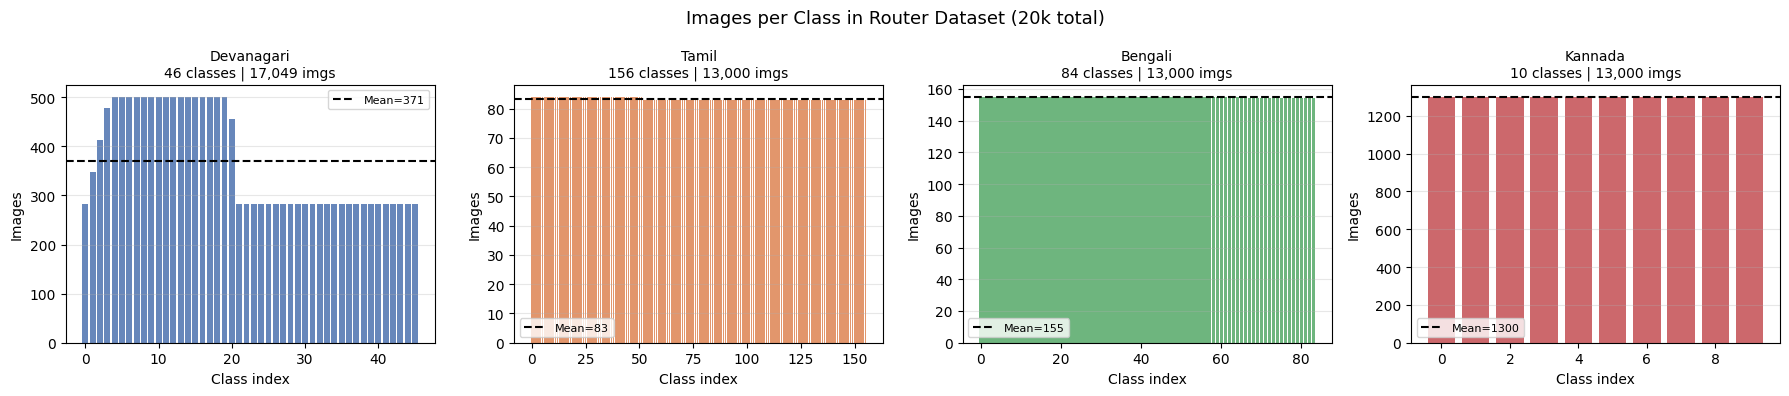

Saved → router_dataset_distribution.png


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Images per Class in Router Dataset (20k total)', fontsize=13)

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for ax, script, color in zip(axes, SCRIPTS, colors):
    script_dir = OUT_ROOT / script
    cls_dirs   = sorted([d for d in script_dir.iterdir() if d.is_dir()])
    cls_names  = [d.name for d in cls_dirs]
    cls_counts = [sum(1 for _ in d.glob('*.png')) for d in cls_dirs]

    if not cls_counts:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                transform=ax.transAxes, fontsize=12)
        ax.set_title(script.capitalize())
        continue

    ax.bar(range(len(cls_counts)), cls_counts, color=color, alpha=0.85)
    ax.axhline(np.mean(cls_counts), color='black', lw=1.5, ls='--',
               label=f'Mean={np.mean(cls_counts):.0f}')
    ax.set_title(f'{script.capitalize()}\n'
                 f'{len(cls_counts)} classes | {sum(cls_counts):,} imgs',
                 fontsize=10)
    ax.set_xlabel('Class index')
    ax.set_ylabel('Images')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/router_dataset_distribution.png',
            dpi=130, bbox_inches='tight')
plt.show()
print('Saved → router_dataset_distribution.png')

## 10. Visual Sanity Check — Sample Grid

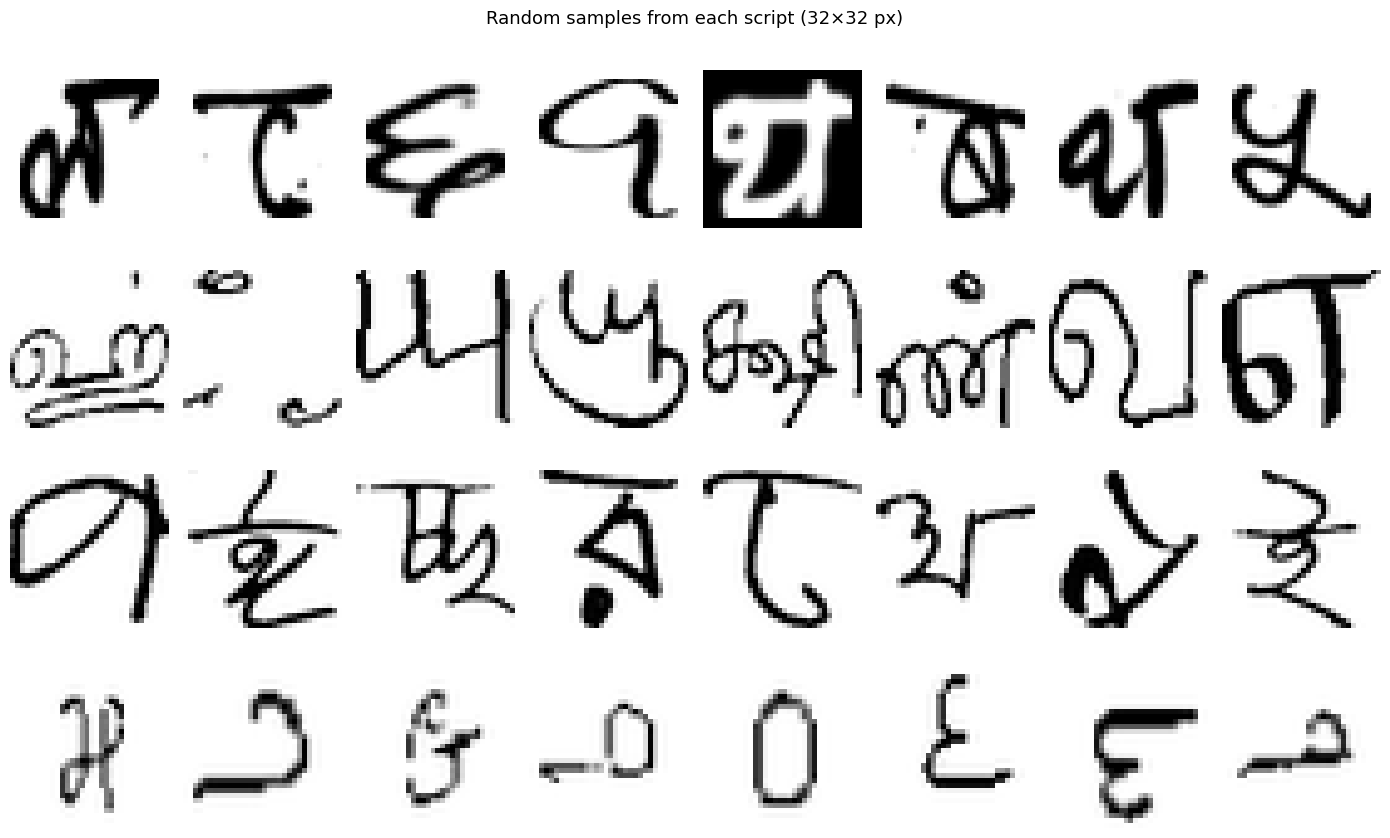

Saved → router_sample_grid.png


In [22]:
# Show 8 random images from each script
COLS = 8
n_scripts = sum(1 for s in SCRIPTS
                if any((OUT_ROOT/s).rglob('*.png')))

fig, axes = plt.subplots(n_scripts, COLS, figsize=(14, 2.2 * n_scripts))
fig.suptitle('Random samples from each script (32×32 px)', fontsize=13)

if n_scripts == 1:
    axes = axes[np.newaxis, :]

row = 0
for script in SCRIPTS:
    all_imgs = list((OUT_ROOT / script).rglob('*.png'))
    if not all_imgs:
        continue
    chosen = random.sample(all_imgs, min(COLS, len(all_imgs)))
    for col, p in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(Image.open(p), cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        # Label first column with script name
        if col == 0:
            ax.set_ylabel(script.capitalize(), fontsize=10,
                          rotation=0, labelpad=55, va='center')
    row += 1

plt.tight_layout()
plt.savefig('/kaggle/working/router_sample_grid.png',
            dpi=130, bbox_inches='tight')
plt.show()
print('Saved → router_sample_grid.png')

## 11. Save Dataset Manifest (JSON)

In [23]:
# Build a manifest so the router training notebook knows exactly what's here
manifest = {
    'total_images'    : grand_total,
    'images_per_script': IMAGES_PER_SCRIPT,
    'img_size'        : IMG_OUT_SIZE,
    'scripts'         : {}
}

for script in SCRIPTS:
    script_dir = OUT_ROOT / script
    cls_dirs   = sorted([d for d in script_dir.iterdir() if d.is_dir()])
    manifest['scripts'][script] = {
        'label_index' : SCRIPTS.index(script),
        'path'        : str(script_dir),
        'num_classes' : len(cls_dirs),
        'num_images'  : actual_counts[script]['images'],
        'classes'     : [d.name for d in cls_dirs],
    }

manifest_path = OUT_ROOT / 'manifest.json'
with open(manifest_path, 'w') as f:
    json.dump(manifest, f, indent=2)

print(f'Manifest saved → {manifest_path}')
print(json.dumps({k: v for k, v in manifest.items() if k != 'scripts'}, indent=2))

Manifest saved → /kaggle/working/router_dataset/manifest.json
{
  "total_images": 56049,
  "images_per_script": 13000,
  "img_size": 32
}


## 12. Final File Listing

In [24]:
print('Output directory tree (top 2 levels):')
print(f'{OUT_ROOT}/')
for script_dir in sorted(OUT_ROOT.iterdir()):
    if script_dir.is_dir():
        cls_dirs  = sorted([d for d in script_dir.iterdir() if d.is_dir()])
        n_imgs    = sum(1 for _ in script_dir.rglob('*.png'))
        print(f'  ├── {script_dir.name}/    [{len(cls_dirs)} class folders | {n_imgs:,} images]')
        for cls_dir in cls_dirs[:4]:
            n = sum(1 for _ in cls_dir.glob('*.png'))
            print(f'  │     ├── {cls_dir.name}/  ({n} imgs)')
        if len(cls_dirs) > 4:
            print(f'  │     └── ... ({len(cls_dirs)-4} more class folders)')
    else:
        size_kb = script_dir.stat().st_size / 1024
        print(f'  ├── {script_dir.name}  ({size_kb:.1f} KB)')

print(f'\n✓ Router dataset ready at: {OUT_ROOT}')
print(f'  Pass --data_root {OUT_ROOT} to your router training script.')

Output directory tree (top 2 levels):
/kaggle/working/router_dataset/
  ├── bengali/    [84 class folders | 13,000 images]
  │     ├── class_01/  (155 imgs)
  │     ├── class_02/  (155 imgs)
  │     ├── class_03/  (155 imgs)
  │     ├── class_04/  (155 imgs)
  │     └── ... (80 more class folders)
  ├── devanagari/    [46 class folders | 17,049 images]
  │     ├── character_10_yna/  (283 imgs)
  │     ├── character_11_taamatar/  (348 imgs)
  │     ├── character_12_thaa/  (413 imgs)
  │     ├── character_13_daa/  (478 imgs)
  │     └── ... (42 more class folders)
  ├── kannada/    [10 class folders | 13,000 images]
  │     ├── class_0/  (1300 imgs)
  │     ├── class_1/  (1300 imgs)
  │     ├── class_2/  (1300 imgs)
  │     ├── class_3/  (1300 imgs)
  │     └── ... (6 more class folders)
  ├── manifest.json  (7.0 KB)
  ├── tamil/    [156 class folders | 13,000 images]
  │     ├── class_001/  (84 imgs)
  │     ├── class_002/  (84 imgs)
  │     ├── class_003/  (84 imgs)
  │     ├── class_0

In [25]:
!zip -r router_dataset.zip /kaggle/working/router_dataset

  adding: kaggle/working/router_dataset/ (stored 0%)
  adding: kaggle/working/router_dataset/bengali/ (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/ (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002781.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002672.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002745.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002755.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002729.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002667.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002763.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002757.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img_002735.png (stored 0%)
  adding: kaggle/working/router_dataset/bengali/class_25/img